# Análisis vectorial y ráster de Colombia con GeoPandas

**Parte 1 – Biblioteca principal: GeoPandas** (con apoyo de Shapely y Rasterio)

## 1. Problema geográfico
¿Cómo se distribuye la población urbana entre los departamentos de Colombia y cómo se relaciona con el relieve y la red hídrica?
Se buscan los departamentos con **mayor densidad de población urbana** (suma de la población de sus ciudades por km²) y se contrasta con su relieve y con la longitud de ríos que los atraviesan.

## 2. Procedencia de los datos
Todos los datos provienen de [Natural Earth](https://www.naturalearthdata.com/downloads/) (dominio público, sin restricciones de uso):

| Capa | Tipo | Escala | Uso |
|---|---|---|---|
| `ne_10m_admin_1_states_provinces` | Vector (polígonos) | 1:10m | Departamentos |
| `ne_10m_populated_places` | Vector (puntos) | 1:10m | Ciudades y población |
| `ne_10m_rivers_lake_centerlines` | Vector (líneas) | 1:10m | Ríos |
| `SR_50M` | Ráster (1 banda, relieve sombreado en grises) | 1:50m | Relieve |

> **Limitación:** `SR_50M` es un relieve sombreado, no un modelo de elevación (DEM). Sus valores sirven como *indicador* de relieve, no como metros sobre el nivel del mar.

## 3. Preparación del entorno

In [1]:
import importlib.util
import subprocess
import urllib.request
import zipfile
from pathlib import Path

# Colab incluye geopandas y shapely; rasterio se instala solo si falta
if importlib.util.find_spec("rasterio") is None:
    subprocess.run(["uv", "pip", "install", "--system", "-q", "rasterio"], check=True)

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio import features
from rasterio.mask import mask
from rasterio.plot import plotting_extent
from scipy.ndimage import generic_filter
from shapely.geometry import Polygon, shape
from shapely.ops import nearest_points

CRS_METRICO = "EPSG:9377"  # MAGNA-SIRGAS Origen Nacional (metros)

## 4. Descarga de datos

In [2]:
BASE = "https://naciscdn.org/naturalearth"
DATOS = Path("data")

def descargar(ruta):
    """Descarga y descomprime un recurso de Natural Earth (si no existe ya)."""
    nombre = Path(ruta).stem
    destino = DATOS / nombre
    if not destino.exists():
        DATOS.mkdir(exist_ok=True)
        zip_local = DATOS / f"{nombre}.zip"
        urllib.request.urlretrieve(f"{BASE}/{ruta}", zip_local)
        with zipfile.ZipFile(zip_local) as z:
            z.extractall(destino)
        zip_local.unlink()
    return destino

d_deptos = descargar("10m/cultural/ne_10m_admin_1_states_provinces.zip")
d_ciudades = descargar("10m/cultural/ne_10m_populated_places.zip")
d_rios = descargar("10m/physical/ne_10m_rivers_lake_centerlines.zip")
d_relieve = descargar("50m/raster/SR_50M.zip")

## 5. Datos vectoriales: lectura y consulta de atributos
**Operación 1 – Lectura y filtrado.** Se leen los shapefiles y se filtran las entidades de Colombia por código de país.

In [3]:
deptos = gpd.read_file(d_deptos).query("adm0_a3 == 'COL'")[["name", "type", "geometry"]]
deptos = deptos.rename(columns={"name": "departamento"}).reset_index(drop=True)

ciudades = gpd.read_file(d_ciudades).query("ADM0_A3 == 'COL'")[["NAME", "POP_MAX", "FEATURECLA", "geometry"]]
ciudades = ciudades.rename(columns={"NAME": "ciudad", "POP_MAX": "poblacion"}).reset_index(drop=True)

rios = gpd.read_file(d_rios)[["name", "geometry"]]

print(f"{len(deptos)} departamentos | {len(ciudades)} ciudades | {len(rios)} tramos de ríos (mundo)")
print("CRS original:", deptos.crs)
deptos.head()

34 departamentos | 72 ciudades | 1473 tramos de ríos (mundo)
CRS original: EPSG:4326


,departamento,type,geometry
0,Nariño,Departamento,"MULTIPOLYGON (((-78.64127 1.25941, -78.66468 1..."
1,Putumayo,Intendencia,"POLYGON ((-76.17759 0.40013, -76.20209 0.40179..."
2,Chocó,Departamento,"MULTIPOLYGON (((-77.46937 8.53781, -77.44113 8..."
3,Guainía,Comisaría,"POLYGON ((-67.06523 1.17269, -67.08611 1.176, ..."
4,Vaupés,Comisaría,"POLYGON ((-69.84118 1.70758, -69.85617 1.70767..."


In [4]:
# Consulta por atributos: las 5 ciudades más pobladas
ciudades.nlargest(5, "poblacion")[["ciudad", "poblacion"]]

,ciudad,poblacion
71,Bogota,7772000
69,Medellín,3297000
70,Cali,2254000
65,Barranquilla,1798000
56,Bucaramanga,1009000


## 6. Reproyección y cálculo de áreas
**Operación 2 – Reproyección y áreas.** Los datos vienen en grados (EPSG:4326), que no sirven para medir áreas ni distancias. Se reproyectan a EPSG:9377 (metros) antes de calcular.

In [5]:
deptos = deptos.to_crs(CRS_METRICO)
ciudades = ciudades.to_crs(CRS_METRICO)

deptos["area_km2"] = deptos.area / 1e6
print(f"Área total: {deptos.area_km2.sum():,.0f} km² (referencia oficial ≈ 1.141.748 km²)")
deptos.sort_values("area_km2", ascending=False)[["departamento", "type", "area_km2"]].head(8).round(0)

Área total: 1,135,645 km² (referencia oficial ≈ 1.141.748 km²)


,departamento,type,area_km2
5,Amazonas,Comisaría,109206.0
11,Vichada,Comisaría,98874.0
22,Caquetá,Intendencia,89972.0
27,Meta,Departamento,86109.0
3,Guainía,Comisaría,71594.0
14,Antioquia,Departamento,63388.0
24,Guaviare,Comisaría,54975.0
4,Vaupés,Comisaría,51766.0


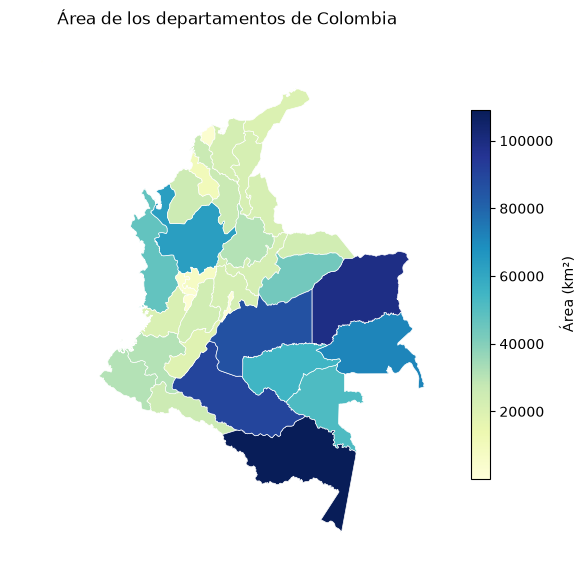

In [6]:
fig, ax = plt.subplots(figsize=(7, 8))
deptos.plot(column="area_km2", cmap="YlGnBu", legend=True, edgecolor="white", linewidth=0.5, ax=ax,
            legend_kwds={"label": "Área (km²)", "shrink": 0.6})
ax.set_title("Área de los departamentos de Colombia")
ax.set_axis_off()
plt.show()

## 7. Combinación de capas
**Operación 3 – Unión espacial (`sjoin`).** Se asigna cada ciudad a su departamento y se agrega población y número de ciudades.

**Operación 4 – Recorte e intersección de líneas con polígonos (`clip` / `overlay`).** Se recortan los ríos a Colombia y se mide cuántos km de río hay en cada departamento.

In [7]:
# Ciudades -> departamento (algunas ciudades costeras o insulares pueden quedar fuera del polígono)
ciu_dep = gpd.sjoin(ciudades, deptos[["departamento", "geometry"]], how="left", predicate="within")
print("Ciudades sin departamento asignado:", ciu_dep.departamento.isna().sum())

resumen = (ciu_dep.groupby("departamento")
           .agg(n_ciudades=("ciudad", "count"), pob_urbana=("poblacion", "sum"))
           .reset_index())
deptos = deptos.drop(columns=["n_ciudades", "pob_urbana"], errors="ignore").merge(resumen, on="departamento", how="left")
deptos[["n_ciudades", "pob_urbana"]] = deptos[["n_ciudades", "pob_urbana"]].fillna(0)
deptos["densidad_urbana"] = deptos.pob_urbana / deptos.area_km2

Ciudades sin departamento asignado: 1


In [8]:
# Ríos recortados al territorio colombiano (se recorta antes de reproyectar: los ríos
# de otras latitudes no se proyectan bien a un CRS local) y longitud por departamento
rios_col = gpd.clip(rios, deptos.to_crs(rios.crs).union_all()).to_crs(CRS_METRICO)
rios_dep = gpd.overlay(rios_col, deptos[["departamento", "geometry"]], how="intersection")
rios_dep["km"] = rios_dep.length / 1000

deptos = deptos.merge(rios_dep.groupby("departamento").km.sum().rename("km_rios"), on="departamento", how="left")
deptos["km_rios"] = deptos.km_rios.fillna(0)
deptos.sort_values("km_rios", ascending=False)[["departamento", "km_rios"]].head(5).round(0)

,departamento,km_rios
5,Amazonas,1356.0
27,Meta,774.0
11,Vichada,771.0
3,Guainía,767.0
14,Antioquia,636.0


## 8. Reto: departamentos con mayor densidad urbana
Se seleccionan los departamentos que cumplen **ambas** condiciones: densidad urbana en el cuartil superior (percentil 75) y al menos 1 millón de habitantes urbanos.
El segundo filtro descarta departamentos pequeños con una población urbana poco relevante en términos absolutos.

In [9]:
umbral = deptos.densidad_urbana.quantile(0.75)
deptos["reto"] = (deptos.densidad_urbana >= umbral) & (deptos.pob_urbana >= 1_000_000)
reto = deptos[deptos.reto]

print(f"Umbral de densidad urbana (P75): {umbral:.1f} hab/km²")
reto.sort_values("densidad_urbana", ascending=False)[
    ["departamento", "n_ciudades", "pob_urbana", "area_km2", "densidad_urbana", "km_rios"]].round(1)

Umbral de densidad urbana (P75): 39.8 hab/km²


,departamento,n_ciudades,pob_urbana,area_km2,densidad_urbana,km_rios
28,Bogota,1.0,7772000.0,1668.1,4659.3,0.7
18,Atlántico,3.0,2565387.0,3341.2,767.8,103.1
13,Valle del Cauca,4.0,2807133.0,20922.9,134.2,231.4
14,Antioquia,6.0,3955293.0,63388.2,62.4,636.2
17,Bolívar,4.0,1098698.0,26441.1,41.6,587.2
29,Santander,3.0,1225298.0,30723.1,39.9,18.7


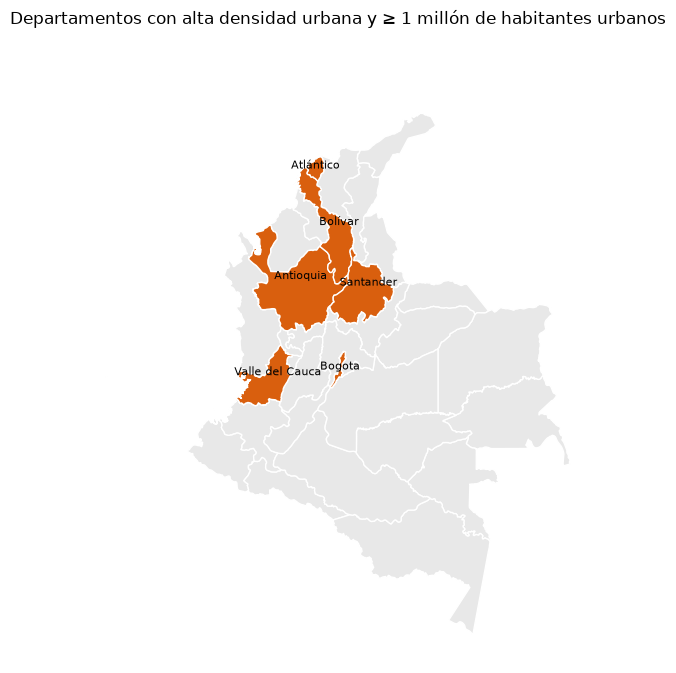

In [10]:
fig, ax = plt.subplots(figsize=(7, 8))
deptos.plot(color="#e8e8e8", edgecolor="white", ax=ax)
reto.plot(color="#d95f0e", edgecolor="white", ax=ax)
for _, r in reto.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r.departamento, (p.x, p.y), ha="center", fontsize=8)
ax.set_title("Departamentos con alta densidad urbana y ≥ 1 millón de habitantes urbanos")
ax.set_axis_off()
plt.show()

## 9. Operaciones geométricas con Shapely
GeoPandas usa Shapely internamente; aquí se usa directamente para análisis de proximidad alrededor de Bogotá:
`buffer`, `intersection`, `nearest_points`, `Polygon` y predicados espaciales.

In [11]:
bogota = ciudades.loc[ciudades.ciudad.str.contains("Bogot"), "geometry"].iloc[0]
zona = bogota.buffer(150_000)  # radio de 150 km (CRS en metros)

# Porcentaje del área de cada departamento que cae dentro de la zona
deptos["pct_en_zona"] = deptos.geometry.apply(lambda g: g.intersection(zona).area / g.area * 100)
print(deptos[deptos.pct_en_zona > 0].sort_values("pct_en_zona", ascending=False)[["departamento", "pct_en_zona"]].round(1).to_string(index=False))

# Ciudades dentro de la zona y distancia a Bogotá
en_zona = ciudades[ciudades.geometry.within(zona)].copy()
en_zona["dist_km"] = en_zona.geometry.distance(bogota) / 1000
en_zona.sort_values("dist_km")[["ciudad", "poblacion", "dist_km"]].round(1).head(8)

departamento  pct_en_zona
Cundinamarca        100.0
      Bogota        100.0
      Tolima         53.6
      Boyacá         42.1
      Caldas         35.5
        Meta         19.8
    Casanare          4.8
   Santander          3.8
       Huila          3.6
   Risaralda          1.7
     Quindío          1.1
   Antioquia          0.2


,ciudad,poblacion,dist_km
71,Bogota,7772000,0.0
61,Villavicencio,374763,70.1
5,Girardot,130289,86.5
29,Honda,35469,98.5
52,San Martín,16273,109.5
21,Chiquinquirá,53975,116.7
57,Ibagué,421685,128.4
20,Tunja,161412,131.7


In [12]:
# Vecinos de Cundinamarca (predicado `touches`) y punto del río más cercano a Bogotá
cund = deptos.loc[deptos.departamento == "Cundinamarca", "geometry"].iloc[0]
vecinos = deptos[deptos.geometry.touches(cund)].departamento.tolist()
print("Vecinos de Cundinamarca:", vecinos)

rio_cercano = nearest_points(bogota, rios_col.union_all())[1]
print(f"Río más cercano a Bogotá: {bogota.distance(rio_cercano) / 1000:.1f} km")

# Polígono definido a mano (caja de ~100 km) y ciudades que contiene
caja = Polygon([(bogota.x - 5e4, bogota.y - 5e4), (bogota.x + 5e4, bogota.y - 5e4),
                (bogota.x + 5e4, bogota.y + 5e4), (bogota.x - 5e4, bogota.y + 5e4)])
print("Ciudades en la caja:", ciudades[ciudades.geometry.within(caja)].ciudad.tolist())

Vecinos de Cundinamarca: ['Boyacá', 'Huila', 'Caldas', 'Casanare', 'Meta', 'Bogota', 'Tolima']
Río más cercano a Bogotá: 18.3 km
Ciudades en la caja: ['Villavicencio', 'Bogota']


## 10. Datos ráster con Rasterio
Se integra el ráster de relieve con los vectores:
1. Metadatos y recorte al territorio colombiano.
2. Estadística zonal por departamento (ráster → atributo vectorial).
3. Ráster → vector (`features.shapes`) y vector → ráster (`features.rasterize`).

In [13]:
ruta_tif = next(d_relieve.glob("*.tif"))
with rasterio.open(ruta_tif) as src:
    print("CRS:", src.crs, "| Tamaño:", src.width, "x", src.height, "| Bandas:", src.count, "| Tipo:", src.dtypes[0])
    print("Resolución (°):", src.res, "| Límites:", src.bounds)

    # Recorte con la geometría de Colombia (el ráster está en EPSG:4326)
    col_4326 = deptos.to_crs(src.crs)
    recorte, transf = mask(src, col_4326.geometry, crop=True, nodata=0)
    crs_ras = src.crs

# Una sola banda en escala de grises: 0 (sombra) a 255 (iluminado); 0 también es el valor fuera de Colombia
gris = recorte[0].astype(float)
print("Recorte:", recorte.shape)

CRS: EPSG:4326 | Tamaño: 10800 x 5400 | Bandas: 1 | Tipo: uint8
Resolución (°): (0.03333333333333, 0.03333333333333) | Límites: BoundingBox(left=-179.99999999999997, bottom=-89.99999999998201, right=179.99999999996405, top=90.0)
Recorte: (1, 536, 446)


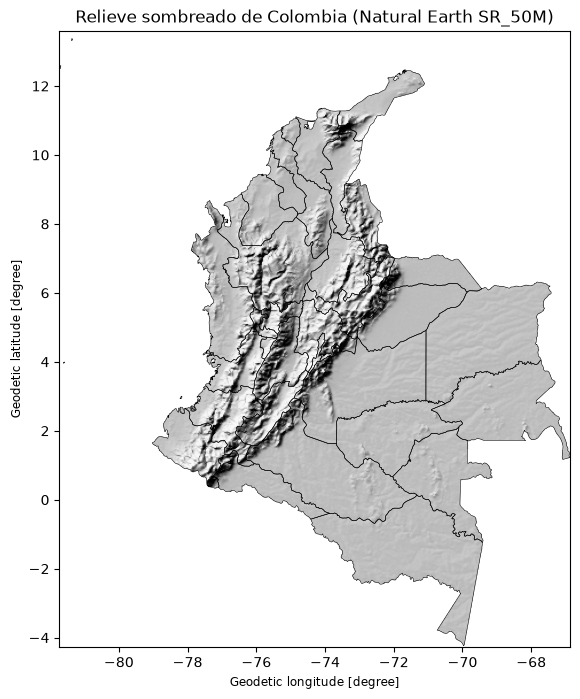

In [14]:
def mostrar_relieve(ax):
    """Dibuja el relieve en grises, ocultando lo que queda fuera de Colombia."""
    ax.imshow(np.ma.masked_equal(gris, 0), cmap="gray", extent=plotting_extent(recorte[0], transf))

fig, ax = plt.subplots(figsize=(7, 8))
mostrar_relieve(ax)
col_4326.boundary.plot(ax=ax, color="black", linewidth=0.4)
ax.set_title("Relieve sombreado de Colombia (Natural Earth SR_50M)")
plt.show()

In [15]:
# Estadística zonal: brillo medio y variabilidad del relieve por departamento
# Se rasteriza cada departamento con el mismo grid del recorte y se agregan los píxeles.
ids = np.arange(1, len(col_4326) + 1)
etiquetas = features.rasterize(zip(col_4326.geometry, ids), out_shape=gris.shape, transform=transf, fill=0, dtype="int32")

deptos["relieve_medio"] = [gris[etiquetas == i].mean() if (etiquetas == i).any() else np.nan for i in ids]
deptos["relieve_std"] = [gris[etiquetas == i].std() if (etiquetas == i).any() else np.nan for i in ids]

# Un std alto indica mayor contraste de sombras, es decir, relieve más accidentado
deptos.nlargest(5, "relieve_std")[["departamento", "relieve_medio", "relieve_std"]].round(1)

,departamento,relieve_medio,relieve_std
33,Risaralda,184.6,58.7
10,Boyacá,175.2,58.2
30,Tolima,161.4,58.0
23,Huila,180.6,56.8
25,Caldas,184.9,53.9


In [16]:
# Ráster -> vector: zonas de relieve accidentado (std local alto) convertidas a polígonos
std_local = generic_filter(gris, np.std, size=5)
accidentado = ((std_local > np.nanpercentile(std_local[gris > 0], 85)) & (gris > 0)).astype("uint8")

formas = features.shapes(accidentado, mask=accidentado == 1, transform=transf)
zonas = gpd.GeoDataFrame(geometry=[shape(g) for g, _ in formas], crs=crs_ras)
zonas = zonas.to_crs(CRS_METRICO)
zonas["area_km2"] = zonas.area / 1e6
print(f"{len(zonas)} polígonos de relieve accidentado | área total: {zonas.area_km2.sum():,.0f} km²")

72 polígonos de relieve accidentado | área total: 170,240 km²


## 11. Mapa final y conclusiones

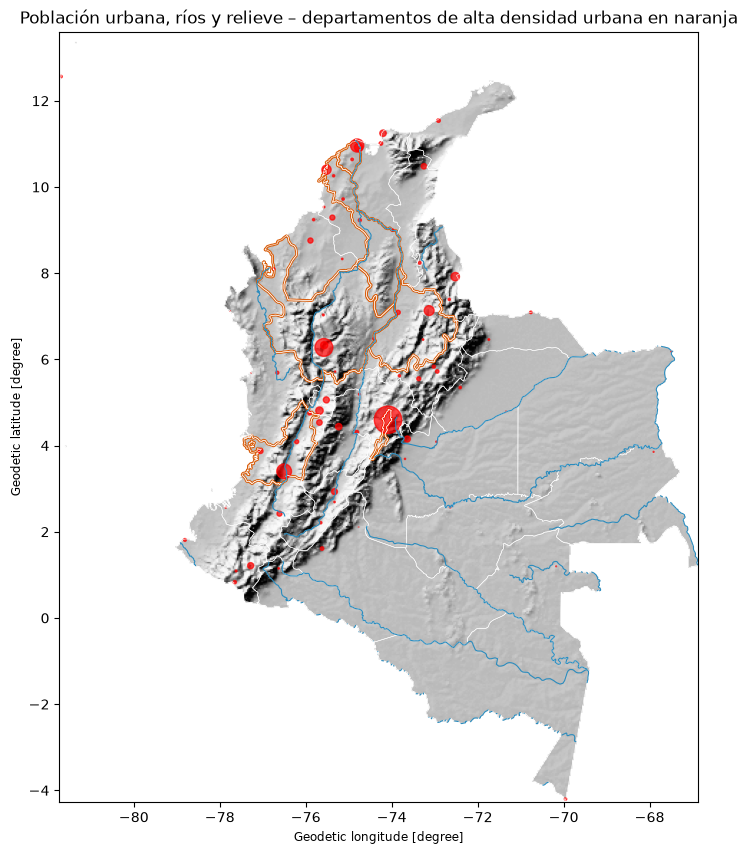

In [17]:
fig, ax = plt.subplots(figsize=(9, 10))
mostrar_relieve(ax)
deptos.to_crs(crs_ras).boundary.plot(ax=ax, color="white", linewidth=0.4)
reto.to_crs(crs_ras).plot(ax=ax, facecolor="none", edgecolor="#d95f0e", linewidth=2)
rios_col.to_crs(crs_ras).plot(ax=ax, color="#2b8cbe", linewidth=0.8)
ciudades.to_crs(crs_ras).plot(ax=ax, markersize=ciudades.poblacion / 20000, color="red", alpha=0.7)
ax.set_title("Población urbana, ríos y relieve – departamentos de alta densidad urbana en naranja")
plt.show()

In [18]:
deptos[["departamento", "area_km2", "pob_urbana", "densidad_urbana", "km_rios", "relieve_std"]].corr(numeric_only=True).round(2)

,area_km2,pob_urbana,densidad_urbana,km_rios,relieve_std
area_km2,1.00,-0.21,-0.24,0.82,-0.29
pob_urbana,-0.21,1.00,0.85,-0.11,0.17
densidad_urbana,-0.24,0.85,1.00,-0.17,0.02
km_rios,0.82,-0.11,-0.17,1.00,-0.31
relieve_std,-0.29,0.17,0.02,-0.31,1.00


**Interpretación**
- Seis departamentos superan el umbral del reto: Bogotá D.C. (≈ 4.660 hab/km²), Atlántico (≈ 770), Valle del Cauca, Antioquia, Bolívar y Santander. Reúnen las principales ciudades del país, concentradas en la región Andina y el Caribe.
- Los departamentos con más kilómetros de río (Amazonas, Meta, Vichada, Guainía) son extensos y tienen muy poca población urbana: la correlación entre densidad urbana y km de río es débil y negativa (≈ -0,17).
- El relieve más accidentado (mayor `relieve_std`) aparece en departamentos andinos como Risaralda, Boyacá, Tolima, Huila y Caldas. Su correlación con la densidad urbana es casi nula (≈ 0,02), por lo que el relieve por sí solo no explica dónde se concentra la población.
- Limitaciones: las ciudades de Natural Earth son una muestra y no un censo; el ráster es un relieve sombreado y no un DEM, así que `relieve_std` es un indicador relativo y no una altitud.

---
## 12. Parte 2 – Integración de una segunda biblioteca *(a cargo de mi compañero)*

Variables disponibles de la parte 1:

| Variable | Contenido |
|---|---|
| `deptos` | GeoDataFrame de departamentos (EPSG:9377) con área, población urbana, densidad, km de ríos, relieve y bandera `reto` |
| `reto` | Subconjunto de `deptos` que cumple la condición del reto |
| `ciudades` | Ciudades con población (EPSG:9377) |
| `rios_col` | Ríos recortados a Colombia (EPSG:9377) |
| `recorte`, `transf` | Ráster de relieve recortado y su transformación afín (EPSG:4326) |

In [19]:
# Parte 2: tu código aquí

## 13. Evaluación de las herramientas y dificultades
*(Pendiente: utilidad de las herramientas y dificultades encontradas.)*